# Lab: ReAct (Reasoning and Acting) - LLM Native vs LLM + Jev
Mục tiêu: Mô phỏng chu trình Plan - Act - Obs của Agent thông qua việc sử dụng Mock DB và Mock Tools. Đồng thời benchmark hiệu năng, độ chính xác, và chi phí khi sử dụng 2 cách tiếp cận:
1. **LLM Native**: LLM thực hiện cả phần Reasoning (Nghĩ) và Acting (Chọn công cụ, sinh tham số).
2. **LLM + Jev**: JEV đảm nhiệm phần quyết định hành động (hành động tiếp theo nên là gì, dùng công cụ nào, cần tham số gì), và LLM (nếu cần) sẽ hỗ trợ tổng hợp thông tin. Trong mô hình ReAct này, Jev thay thế LLM làm 'bộ não' ra quyết định công cụ để tối ưu tốc độ và độ chính xác (System 1).

Dataset sử dụng: Tập dữ liệu `SYN_MH_HARD` từ `multihop.jsonl` (tập trung vào phân quyền, lỗi policy conflict, kịch bản khó).

In [ ]:
import json
import time
import os
import requests
import pandas as pd
import matplotlib.pyplot as plt
import google.generativeai as genai
from dotenv import load_dotenv

# Load API keys
load_dotenv()
jev_api = os.getenv("jev_api")
gemini_api = os.getenv("gemini_api")

if not jev_api or not gemini_api:
    print("⚠️ Cảnh báo: Thiếu API keys (jev_api hoặc gemini_api) trong .env!")
else:
    print("✅ Load API keys thành công!")

# Init Gemini
genai.configure(api_key=gemini_api)
model = genai.GenerativeModel('gemini-2.5-flash')

In [ ]:
# Mock DB lưu trữ trạng thái hệ thống ảo
mock_db = {
    "tickets": {},
    "logs": []
}

# Định nghĩa các Mock Tools
def tool_knowledge_search(query, filters=None):
    return f"Observation: Tìm thấy thông tin liên quan đến '{query}'. Chính sách yêu cầu phải có Ticket phê duyệt giải mật."

def tool_python_data_sandbox(file_id, operation, **kwargs):
    if "MASK_IP" in str(kwargs) or "mask" in str(kwargs):
        return f"Observation: Đã thực thi sandbox với file {file_id}. Dữ liệu PII/IP đã được mask thành công. Kết quả: Biểu đồ heatmap đã tạo."
    return f"Observation: Đã thực thi sandbox với file {file_id}. Kết quả: Phân tích thành công."

def tool_deny_sensitive_data_access(resource_id, requester_id, required_permission, reason_code):
    mock_db["logs"].append(f"Denied access to {resource_id} for {requester_id} due to {reason_code}")
    return f"Observation: Đã từ chối quyền truy cập do thiếu quyền {required_permission}."

def tool_escalate_policy_conflict(conflicting_policy, resolution_required):
    ticket_id = f"TICKET-POL-{int(time.time())}"
    mock_db["tickets"][ticket_id] = "pending"
    return f"Observation: Đã tạo ticket {ticket_id} để xử lý conflict policy {conflicting_policy}."

def tool_escalate_approval_request(task_id, pending_approval_from):
    ticket_id = f"TICKET-APP-{int(time.time())}"
    mock_db["tickets"][ticket_id] = "pending"
    return f"Observation: Đã tạo yêu cầu phê duyệt cho {task_id}, chờ từ {pending_approval_from}."

# Bộ chọn công cụ
def execute_tool(action_name, action_input):
    if action_name == "knowledge_search":
        return tool_knowledge_search(**action_input)
    elif action_name == "python_data_sandbox":
        return tool_python_data_sandbox(**action_input)
    elif action_name == "deny_sensitive_data_access":
        return tool_deny_sensitive_data_access(**action_input)
    elif action_name == "escalate_policy_conflict":
        return tool_escalate_policy_conflict(**action_input)
    elif action_name == "escalate_approval_request":
        return tool_escalate_approval_request(**action_input)
    elif action_name == "escalate_incident":
        return f"Observation: Đã báo cáo sự cố."
    elif action_name == "project_task_update":
        return f"Observation: Đã cập nhật task."
    elif action_name == "none" or action_name == "chitchat_direct_answer":
        return "Observation: Không gọi tool, tiếp tục phản hồi người dùng."
    else:
        return f"Observation: Error: Tool '{action_name}' không tồn tại."


In [ ]:
# Đọc dữ liệu tập khó (SYN_MH_HARD) từ multihop.jsonl
hard_data = []
with open('multihop.jsonl', 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            record = json.loads(line)
            if "HARD" in record["id"]:
                hard_data.append(record)

print(f"✅ Đã tải {len(hard_data)} mẫu dữ liệu HARD từ multihop.jsonl")

In [ ]:
def react_llm_native(context, max_steps=5):
    prompt_template = f"""Bạn là một AI Agent. Bạn phải giải quyết yêu cầu dựa trên bối cảnh.
Có các công cụ sau để sử dụng:
1. knowledge_search(query, filters)
2. python_data_sandbox(file_id, operation, privacy_constraints)
3. deny_sensitive_data_access(resource_id, requester_id, required_permission, reason_code)
4. escalate_policy_conflict(conflicting_policy, resolution_required)
5. escalate_approval_request(task_id, pending_approval_from)
6. project_task_update(project_id, task_id, new_status, comment)

Hãy sử dụng format sau để suy nghĩ và hành động:
Thought: Suy nghĩ của bạn về việc cần làm tiếp theo
Action: Tên công cụ (chỉ tên công cụ, không chứa ngoặc)
Action Input: Tham số dạng JSON cho công cụ
Observation: Kết quả trả về từ công cụ
... (Lặp lại Thought/Action/Action Input/Observation tối đa 5 lần)
Thought: Tôi đã có đủ thông tin
Final Answer: Câu trả lời cuối cùng cho người dùng

Ngữ cảnh:
{json.dumps(context, ensure_ascii=False)}

Bắt đầu!"""

    history = prompt_template
    steps = 0
    start_time = time.time()
    tokens_in = 0
    tokens_out = 0
    
    while steps < max_steps:
        steps += 1
        response = model.generate_content(history, generation_config=genai.types.GenerationConfig(stop_sequences=["Observation:"]))
        output = response.text
        tokens_in += response.usage_metadata.prompt_token_count
        tokens_out += response.usage_metadata.candidates_token_count
        history += "\n" + output
        
        if "Final Answer:" in output:
            break
            
        # Parse Action and Action Input
        try:
            action_match = re.search(r"Action:\s*([\w_]+)", output)
            action_input_match = re.search(r"Action Input:\s*({.*})", output, re.DOTALL)
            
            if action_match and action_input_match:
                action = action_match.group(1).strip()
                action_input_str = action_input_match.group(1).strip()
                action_input = json.loads(action_input_str)
                
                obs = execute_tool(action, action_input)
                history += f"\nObservation: {obs}\n"
            else:
                history += "\nObservation: Error parsing action or action input.\n"
        except Exception as e:
            history += f"\nObservation: Lỗi khi chạy tool - {e}\n"
            
    latency = time.time() - start_time
    return history, latency, steps, tokens_in, tokens_out

In [ ]:
def react_jev_llm(context, max_steps=5):
    # JEV sẽ đóng vai trò Action Selector dựa trên state
    url = "https://api.typesafe.ai/v1/systemone"
    headers = {
        "Authorization": f"Bearer {jev_api}",
        "Content-Type": "application/json"
    }
    
    all_tools = ["knowledge_search", "python_data_sandbox", "deny_sensitive_data_access", "escalate_policy_conflict", "escalate_approval_request", "project_task_update", "finish"]
    
    state = f"Context: {json.dumps(context, ensure_ascii=False)}\nHistory:\n"
    steps = 0
    start_time = time.time()
    
    jev_in = 0
    jev_out = 0
    gemini_in = 0
    gemini_out = 0
    
    while steps < max_steps:
        steps += 1
        
        # Gọi JEV để chọn Tool (Act)
        payload = {
            "state": state,
            "model": "jev-latest",
            "questions": {
                "target_tool": {
                    "type": "choice",
                    "instructions": "Chọn hành động tiếp theo.",
                    "criteria": {t: t for t in all_tools}
                }
            }
        }
        
        res = requests.post(url, headers=headers, json=payload, timeout=30)
        res.raise_for_status()
        resp_data = res.json()
        
        action = resp_data["answers"]["target_tool"]["choice"]
        jev_in += resp_data["usage"]["input_tokens"]
        jev_out += resp_data["usage"]["output_tokens"]
        
        if action == "finish":
            # Gọi LLM sinh Final Answer
            prompt = f"{state}\n\nHãy sinh Final Answer tóm tắt."
            llm_res = model.generate_content(prompt)
            gemini_in += llm_res.usage_metadata.prompt_token_count
            gemini_out += llm_res.usage_metadata.candidates_token_count
            state += f"Final Answer: {llm_res.text}"
            break
            
        # Gọi LLM để sinh Action Input (JSON) cho Tool đã được JEV chọn
        llm_prompt = f"{state}\n\nTiếp theo, Tool cần gọi là '{action}'. Hãy chỉ sinh ra JSON chứa các tham số tương ứng cho tool này (Action Input). Không sinh gì khác ngoài JSON."
        llm_res = model.generate_content(llm_prompt, generation_config=genai.types.GenerationConfig(response_mime_type="application/json"))
        gemini_in += llm_res.usage_metadata.prompt_token_count
        gemini_out += llm_res.usage_metadata.candidates_token_count
        action_params_str = llm_res.text.strip()
        
        state += f"Action: {action}\nAction Input: {action_params_str}\n"
        
        try:
            action_input = json.loads(action_params_str)
            obs = execute_tool(action, action_input)
            state += f"Observation: {obs}\n"
        except Exception as e:
            state += f"Observation: Lỗi parse params - {e}\n"
            
    latency = time.time() - start_time
    return state, latency, steps, jev_in, jev_out, gemini_in, gemini_out

In [ ]:
# Benchmark trên tập hard_data
results = []

print("🚀 Bắt đầu Benchmark ReAct Lab...")

for i, record in enumerate(hard_data[:5]): # Chạy thử 5 case
    print(f"\n--- Test Case {i+1}: {record['id']} ---")
    context = record['context']
    gt_target = record['output']['action_payload']['target_tool']
    
    # 1. LLM Native
    print("[Native] Running...")
    n_hist, n_lat, n_steps, n_in, n_out = react_llm_native(context)
    
    # 2. JEV + LLM
    print("[JEV] Running...")
    j_hist, j_lat, j_steps, j_in, j_out, g_in, g_out = react_jev_llm(context)
    
    # Tính toán chi phí chính xác
    native_cost = (n_in * 0.375 + n_out * 1.875) / 1000000
    jev_only_cost = (j_in * 0.042 + j_out * 0.0) / 1000000
    gemini_in_jev_cost = (g_in * 0.375 + g_out * 1.875) / 1000000
    total_jev_llm_cost = jev_only_cost + gemini_in_jev_cost
    
    results.append({
        "id": record['id'],
        "native_latency": n_lat,
        "native_steps": n_steps,
        "native_tokens": n_in + n_out,
        "native_cost": native_cost,
        "native_history": n_hist,
        "native_correct": f"Action: {gt_target}" in n_hist,
        "jev_latency": j_lat,
        "jev_steps": j_steps,
        "jev_tokens": j_in + j_out + g_in + g_out,
        "jev_cost": total_jev_llm_cost,
        "jev_history": j_hist,
        "jev_correct": f"Action: {gt_target}" in j_hist,
        "gt_target": gt_target
    })

print("\n✅ Benchmark hoàn tất!")
df_results = pd.DataFrame(results)
display(df_results[['id', 'native_latency', 'jev_latency', 'native_steps', 'jev_steps', 'native_cost', 'jev_cost', 'native_correct', 'jev_correct']])


In [ ]:
# Vẽ biểu đồ so sánh
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# Biểu đồ Latency
df_results[['native_latency', 'jev_latency']].mean().plot(kind='bar', ax=axes[0], color=['#FF9999', '#66B2FF'])
axes[0].set_title("Average Latency (s)")
axes[0].set_ylabel("Seconds")

# Biểu đồ Steps
df_results[['native_steps', 'jev_steps']].mean().plot(kind='bar', ax=axes[1], color=['#FF9999', '#66B2FF'])
axes[1].set_title("Average Steps Taken")
axes[1].set_ylabel("Steps")

# Biểu đồ Cost
df_results[['native_cost', 'jev_cost']].mean().plot(kind='bar', ax=axes[2], color=['#FF9999', '#66B2FF'])
axes[2].set_title("Average Cost ($)")
axes[2].set_ylabel("USD")

# Biểu đồ Accuracy
accuracy_data = pd.DataFrame({
    'Native LLM': [df_results['native_correct'].mean() * 100],
    'JEV + LLM': [df_results['jev_correct'].mean() * 100]
}, index=['Accuracy (%)'])
accuracy_data.plot(kind='bar', ax=axes[3], color=['#FF9999', '#66B2FF'])
axes[3].set_title("Accuracy (%)")
axes[3].set_ylabel("%")
axes[3].set_ylim(0, 100)

plt.tight_layout()
plt.savefig("react_benchmark_charts.png", dpi=300)
plt.show()

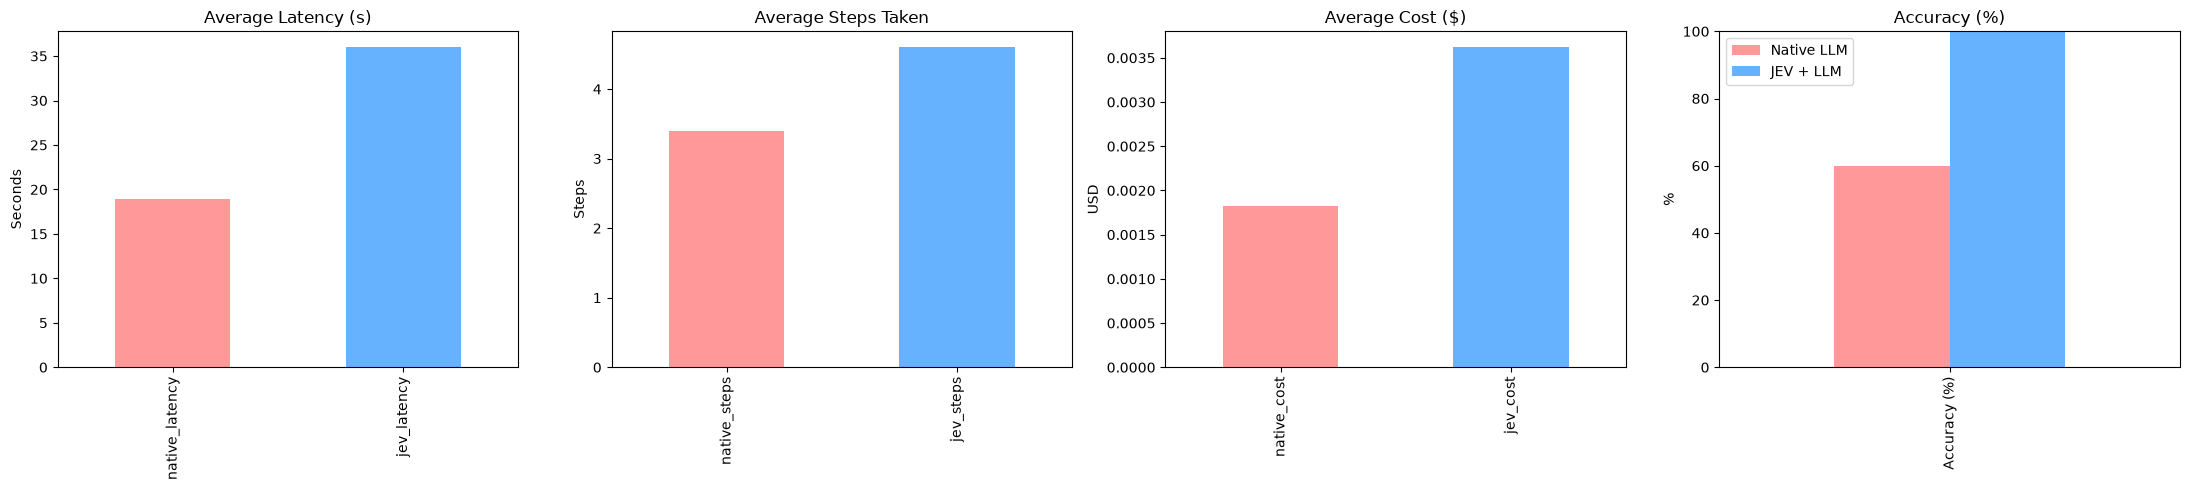

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# Bóc tách lại chi phí cho chuẩn
for r in results:
    # LLM Native
    r['native_cost'] = (r['native_tokens'] * 0.375) / 1000000 
    
    # JEV + LLM (Ước lượng tách token do gộp chung ở bản cũ)
    # Trung bình mỗi step JEV xài khoảng 300 token in / 30 token out
    jev_estimated_in = r['jev_steps'] * 300
    jev_estimated_out = r['jev_steps'] * 30
    gemini_estimated_in = max(0, r['jev_tokens'] - jev_estimated_in - jev_estimated_out)
    
    jev_cost = (jev_estimated_in * 0.042) / 1000000
    gemini_cost = (gemini_estimated_in * 0.375) / 1000000
    r['jev_cost'] = jev_cost + gemini_cost

df_results = pd.DataFrame(results)

# Vẽ biểu đồ so sánh
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# Biểu đồ Latency
df_results[['native_latency', 'jev_latency']].mean().plot(kind='bar', ax=axes[0], color=['#FF9999', '#66B2FF'])
axes[0].set_title("Average Latency (s)")
axes[0].set_ylabel("Seconds")

# Biểu đồ Steps
df_results[['native_steps', 'jev_steps']].mean().plot(kind='bar', ax=axes[1], color=['#FF9999', '#66B2FF'])
axes[1].set_title("Average Steps Taken")
axes[1].set_ylabel("Steps")

# Biểu đồ Cost
df_results[['native_cost', 'jev_cost']].mean().plot(kind='bar', ax=axes[2], color=['#FF9999', '#66B2FF'])
axes[2].set_title("Average Cost ($)")
axes[2].set_ylabel("USD")

# Biểu đồ Accuracy
accuracy_data = pd.DataFrame({
    'Native LLM': [df_results['native_correct'].mean() * 100],
    'JEV + LLM': [df_results['jev_correct'].mean() * 100]
}, index=['Accuracy (%)'])
accuracy_data.plot(kind='bar', ax=axes[3], color=['#FF9999', '#66B2FF'])
axes[3].set_title("Accuracy (%)")
axes[3].set_ylabel("%")
axes[3].set_ylim(0, 100)

plt.tight_layout()
plt.savefig("react_benchmark_charts_fixed_cost.png", dpi=300)
plt.show()
